---

Name : Abhijeet Parmar      
Enrollment No.: 23SOECE11065  
Div.: CE-B    
Roll No.: 22    

---

# <b>Tutorial 5 - Advanced Deep Learning
</b>

---
### <b>Practical 1: Image Generation Using Generative Adversarial Networks (GANs)
</b>

**Definition:** Implement a Generative Adversarial Network (GAN) using Python and TensorFlow/Keras, consisting of a generator and a discriminator, to generate new synthetic images similar to the images in the training dataset. Understand the GAN architecture, adversarial training process, and the interaction between the generator and discriminator.


---

In [2]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt

# Load MNIST dataset
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

# Normalize pixel values between -1 and 1
X_train = (X_train.astype('float32') - 127.5) / 127.5

# Add channel dimension
X_train = X_train.reshape(-1, 28, 28, 1)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (60000, 28, 28, 1)
Testing Data: (10000, 28, 28)


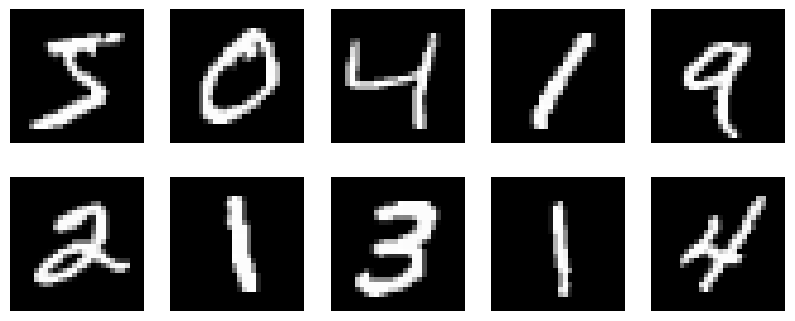

In [3]:
# Display sample images
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i].reshape(28, 28), cmap='gray')
    plt.axis('off')

plt.show()

In [4]:
# Create generator model
generator = keras.Sequential([

    # Input random noise
    keras.layers.Dense(7 * 7 * 128, input_shape=(100,)),

    keras.layers.BatchNormalization(),
    keras.layers.LeakyReLU(),

    # Reshape into feature maps
    keras.layers.Reshape((7, 7, 128)),

    # Upsampling layer
    keras.layers.Conv2DTranspose(
        64, kernel_size=4, strides=2,
        padding='same'
    ),
    keras.layers.BatchNormalization(),
    keras.layers.LeakyReLU(),

    # Generate final image
    keras.layers.Conv2DTranspose(
        1, kernel_size=4, strides=2,
        padding='same', activation='tanh'
    )
])

# Display generator architecture
generator.summary()

C:\Users\abhij\AppData\Roaming\Python\Python314\site-packages\keras\src\layers\core\dense.py:103: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 6272)           │       633,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 6272)           │        25,088 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 64)     │       131,136 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 1)      │         1,025 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 790,977 (3.02 MB)

 Trainable params: 778,305 (2.97 MB)

 Non-trainable params: 12,672 (49.50 KB)

In [5]:
# Create discriminator model
discriminator = keras.Sequential([

    # First convolution layer
    keras.layers.Conv2D(
        64, kernel_size=3, strides=2,
        padding='same', input_shape=(28, 28, 1)
    ),
    keras.layers.LeakyReLU(),
    keras.layers.Dropout(0.3),

    # Second convolution layer
    keras.layers.Conv2D(
        128, kernel_size=3, strides=2,
        padding='same'
    ),
    keras.layers.LeakyReLU(),
    keras.layers.Dropout(0.3),

    # Flatten layer
    keras.layers.Flatten(),

    # Output layer
    keras.layers.Dense(1, activation='sigmoid')
])

# Display discriminator architecture
discriminator.summary()

C:\Users\abhij\AppData\Roaming\Python\Python314\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 14, 14, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 7, 7, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 80,769 (315.50 KB)

 Trainable params: 80,769 (315.50 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
# Define loss function
cross_entropy = keras.losses.BinaryCrossentropy()

# Define optimizers
generator_optimizer = keras.optimizers.Adam(learning_rate=0.0002)
discriminator_optimizer = keras.optimizers.Adam(learning_rate=0.0002)

# Define generator loss
def generator_loss(fake_output):
    return cross_entropy(tf.ones_like(fake_output), fake_output)

# Define discriminator loss
def discriminator_loss(real_output, fake_output):

    real_loss = cross_entropy(
        tf.ones_like(real_output), real_output
    )

    fake_loss = cross_entropy(
        tf.zeros_like(fake_output), fake_output
    )

    return real_loss + fake_loss

print("GAN models compiled successfully.")

GAN models compiled successfully.


In [7]:
# Set training parameters
batch_size = 128
epochs = 10
noise_dim = 100

# Prepare training dataset
train_dataset = tf.data.Dataset.from_tensor_slices(X_train)
train_dataset = train_dataset.shuffle(60000).batch(
    batch_size, drop_remainder=True
)

# Define GAN training step
@tf.function
def train_step(real_images):

    noise = tf.random.normal([batch_size, noise_dim])

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:

        # Generate fake images
        fake_images = generator(noise, training=True)

        # Get discriminator predictions
        real_output = discriminator(real_images, training=True)
        fake_output = discriminator(fake_images, training=True)

        # Calculate losses
        gen_loss = generator_loss(fake_output)
        disc_loss = discriminator_loss(real_output, fake_output)

    # Calculate gradients
    gen_gradients = gen_tape.gradient(
        gen_loss, generator.trainable_variables
    )

    disc_gradients = disc_tape.gradient(
        disc_loss, discriminator.trainable_variables
    )

    # Update model weights
    generator_optimizer.apply_gradients(
        zip(gen_gradients, generator.trainable_variables)
    )

    discriminator_optimizer.apply_gradients(
        zip(disc_gradients, discriminator.trainable_variables)
    )

    return gen_loss, disc_loss


# Train GAN model
for epoch in range(epochs):

    gen_loss = 0
    disc_loss = 0

    for image_batch in train_dataset:
        gen_loss, disc_loss = train_step(image_batch)

    print(
        f"Epoch {epoch + 1}/{epochs}, "
        f"Generator Loss: {gen_loss:.4f}, "
        f"Discriminator Loss: {disc_loss:.4f}"
    )

Epoch 1/10, Generator Loss: 0.9609, Discriminator Loss: 1.0811
Epoch 2/10, Generator Loss: 1.0508, Discriminator Loss: 1.2520
Epoch 3/10, Generator Loss: 1.2888, Discriminator Loss: 0.7570
Epoch 4/10, Generator Loss: 0.7765, Discriminator Loss: 1.3810
Epoch 5/10, Generator Loss: 0.9555, Discriminator Loss: 1.1304
Epoch 6/10, Generator Loss: 0.9810, Discriminator Loss: 1.1107
Epoch 7/10, Generator Loss: 1.0477, Discriminator Loss: 1.1792
Epoch 8/10, Generator Loss: 1.1569, Discriminator Loss: 0.9749
Epoch 9/10, Generator Loss: 1.2901, Discriminator Loss: 1.1494
Epoch 10/10, Generator Loss: 1.2730, Discriminator Loss: 0.8784


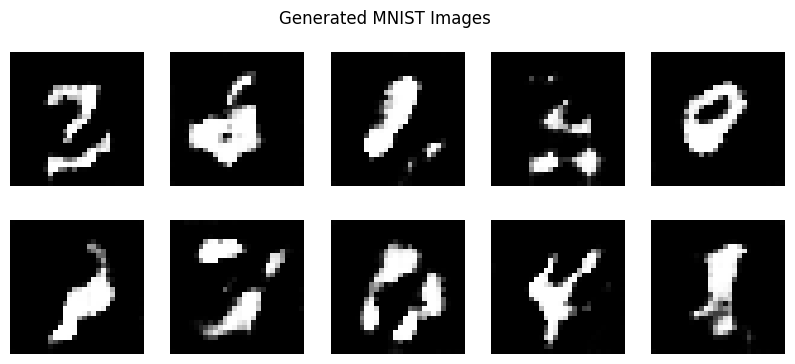

In [8]:
# Generate random noise
noise = tf.random.normal([10, noise_dim])

# Generate synthetic images
generated_images = generator(noise, training=False)

# Display generated images
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(
        generated_images[i, :, :, 0] * 0.5 + 0.5,
        cmap='gray'
    )

    plt.axis('off')

plt.suptitle("Generated MNIST Images")
plt.show()

---
### <b>Practical 2: Image Classification Using Transfer Learning and Fine-Tuning
</b>

**Definition:** Implement an image classification model using transfer learning with a pre-trained CNN architecture such as VGG16, ResNet50, or MobileNetV2. Use pre-trained weights, replace the final classification layer, and fine-tune selected layers to classify images from a custom dataset.


---

In [9]:
import os
import zipfile

# Download Cats and Dogs dataset
url = "https://download.mlcc.google.com/mledu-datasets/cats_and_dogs_filtered.zip"

zip_path = keras.utils.get_file(
    "cats_and_dogs_filtered.zip",
    origin=url
)

# Extract dataset manually
extract_dir = os.path.join(
    os.path.dirname(zip_path),
    "cats_dogs_data"
)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_dir)

# Set dataset directory
base_dir = os.path.join(
    extract_dir,
    "cats_and_dogs_filtered"
)

train_dir = os.path.join(base_dir, "train")
validation_dir = os.path.join(base_dir, "validation")

print("Dataset Downloaded and Extracted Successfully")
print("Training Directory:", train_dir)
print("Training Folder Exists:", os.path.exists(train_dir))
print("Validation Folder Exists:", os.path.exists(validation_dir))

Dataset Downloaded and Extracted Successfully
Training Directory: C:\Users\abhij\.keras\datasets\cats_dogs_data\cats_and_dogs_filtered\train
Training Folder Exists: True
Validation Folder Exists: True


In [10]:
# Set image parameters
image_size = (160, 160)
batch_size = 32

# Load training dataset
train_dataset = keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset='training',
    seed=123,
    image_size=image_size,
    batch_size=batch_size
)

# Load validation dataset
validation_dataset = keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset='validation',
    seed=123,
    image_size=image_size,
    batch_size=batch_size
)

# Display class names
class_names = train_dataset.class_names

print("Classes:", class_names)

Found 2000 files belonging to 2 classes.
Using 1600 files for training.
Found 2000 files belonging to 2 classes.
Using 400 files for validation.
Classes: ['cats', 'dogs']


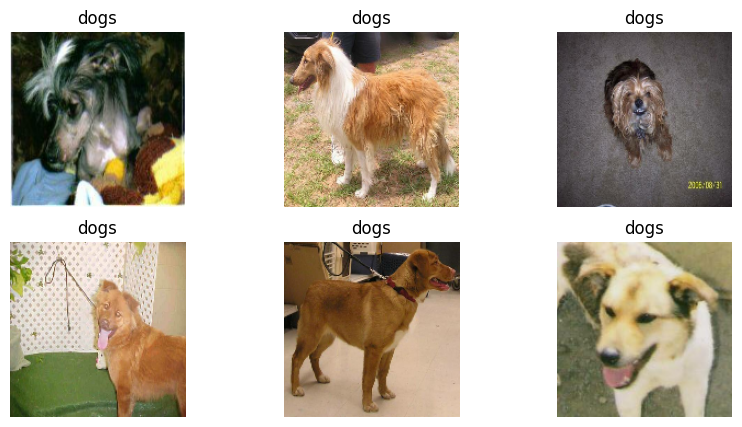

In [11]:
# Display sample images
plt.figure(figsize=(10, 5))

for images, labels in train_dataset.take(1):

    for i in range(6):
        plt.subplot(2, 3, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))

        plt.title(class_names[labels[i]])
        plt.axis('off')

plt.show()

In [12]:
# Load pre-trained MobileNetV2 model
base_model = keras.applications.MobileNetV2(
    input_shape=(160, 160, 3),
    include_top=False,
    weights='imagenet'
)

# Freeze the pre-trained layers
base_model.trainable = False

# Display model summary
base_model.summary()

Model: "mobilenetv2_1.00_160"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 160, 160,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 80, 80,    │        864 │ input_layer_2[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 80, 80,    │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 80, 80,    │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 80, 80,    │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 80, 80,    │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 80, 80,    │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 80, 80,    │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 80, 80,    │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 80, 80,    │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 80, 80,    │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 80, 80,    │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 81, 81,    │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 40, 40,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 40, 40,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 40, 40,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 40, 40,    │      2,304 │ block_1_depthwis

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,257,984 (8.61 MB)

In [13]:
# Build transfer learning model
model = keras.Sequential([

    keras.layers.Input(shape=(160, 160, 3)),

    # Preprocess input images
    keras.layers.Rescaling(1./127.5, offset=-1),

    # Pre-trained MobileNetV2
    base_model,

    # Global average pooling
    keras.layers.GlobalAveragePooling2D(),

    # Dropout layer
    keras.layers.Dropout(0.2),

    # Output layer
    keras.layers.Dense(1, activation='sigmoid')
])

# Display model architecture
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [14]:
# Compile the model
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Train the model
history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=5
)

Epoch 1/5


C:\Users\abhij\AppData\Roaming\Python\Python314\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


50/50 ━━━━━━━━━━━━━━━━━━━━ 11s 185ms/step - accuracy: 0.9069 - loss: 0.2489 - val_accuracy: 0.9775 - val_loss: 0.0891
Epoch 2/5
50/50 ━━━━━━━━━━━━━━━━━━━━ 8s 154ms/step - accuracy: 0.9737 - loss: 0.0892 - val_accuracy: 0.9800 - val_loss: 0.0658
Epoch 3/5
50/50 ━━━━━━━━━━━━━━━━━━━━ 8s 153ms/step - accuracy: 0.9800 - loss: 0.0688 - val_accuracy: 0.9800 - val_loss: 0.0565
Epoch 4/5
50/50 ━━━━━━━━━━━━━━━━━━━━ 7s 149ms/step - accuracy: 0.9812 - loss: 0.0601 - val_accuracy: 0.9825 - val_loss: 0.0507
Epoch 5/5
50/50 ━━━━━━━━━━━━━━━━━━━━ 8s 155ms/step - accuracy: 0.9875 - loss: 0.0497 - val_accuracy: 0.9825 - val_loss: 0.0469


In [15]:
# Unfreeze the base model
base_model.trainable = True

# Freeze earlier layers and train selected last layers
for layer in base_model.layers[:-20]:
    layer.trainable = False

# Keep BatchNormalization layers frozen
for layer in base_model.layers:
    if isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False

# Compile model with a low learning rate
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.00001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Fine-tune the model
fine_tune_history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=3
)

Epoch 1/3
50/50 ━━━━━━━━━━━━━━━━━━━━ 12s 198ms/step - accuracy: 0.9894 - loss: 0.0387 - val_accuracy: 0.9850 - val_loss: 0.0381
Epoch 2/3
50/50 ━━━━━━━━━━━━━━━━━━━━ 8s 169ms/step - accuracy: 0.9919 - loss: 0.0227 - val_accuracy: 0.9875 - val_loss: 0.0375
Epoch 3/3
50/50 ━━━━━━━━━━━━━━━━━━━━ 9s 177ms/step - accuracy: 0.9962 - loss: 0.0162 - val_accuracy: 0.9875 - val_loss: 0.0374


In [16]:
# Evaluate the model
test_loss, test_accuracy = model.evaluate(validation_dataset)

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 124ms/step - accuracy: 0.9875 - loss: 0.0374
Test Loss: 0.0374
Test Accuracy: 98.75 %


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 822ms/step


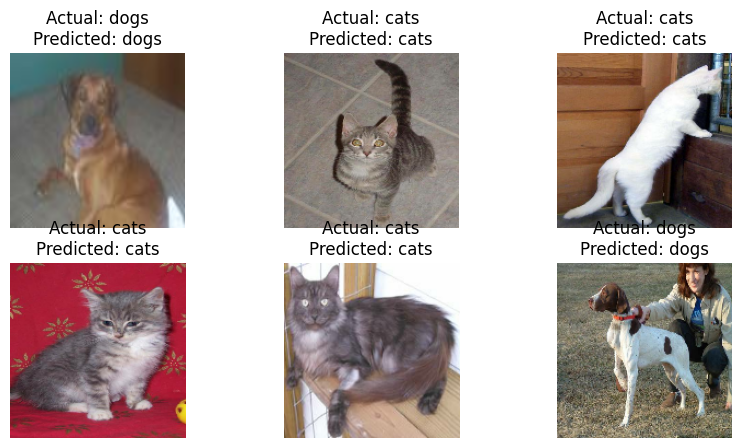

In [17]:
# Predict sample images
for images, labels in validation_dataset.take(1):

    predictions = model.predict(images)

    plt.figure(figsize=(10, 5))

    for i in range(6):

        predicted_label = 1 if predictions[i][0] >= 0.5 else 0

        actual_class = class_names[int(labels[i])]
        predicted_class = class_names[predicted_label]

        plt.subplot(2, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))

        plt.title(
            "Actual: " + actual_class +
            "\nPredicted: " + predicted_class
        )

        plt.axis('off')

    plt.show()

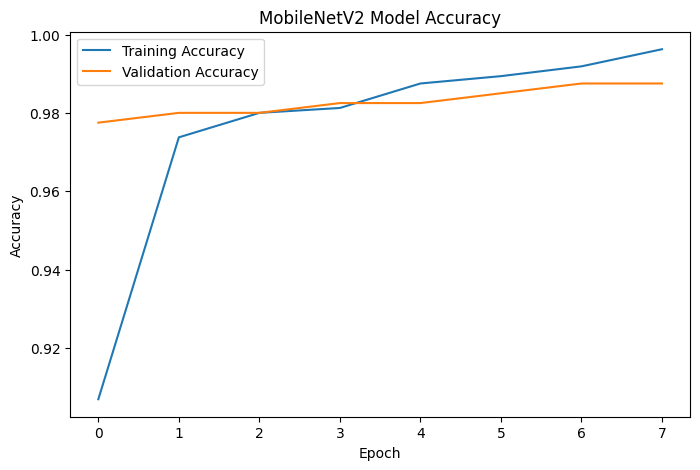

In [18]:
# Combine accuracy values
train_accuracy = (
    history.history['accuracy'] +
    fine_tune_history.history['accuracy']
)

validation_accuracy = (
    history.history['val_accuracy'] +
    fine_tune_history.history['val_accuracy']
)

# Plot accuracy
plt.figure(figsize=(8, 5))

plt.plot(train_accuracy, label='Training Accuracy')
plt.plot(validation_accuracy, label='Validation Accuracy')

plt.title('MobileNetV2 Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

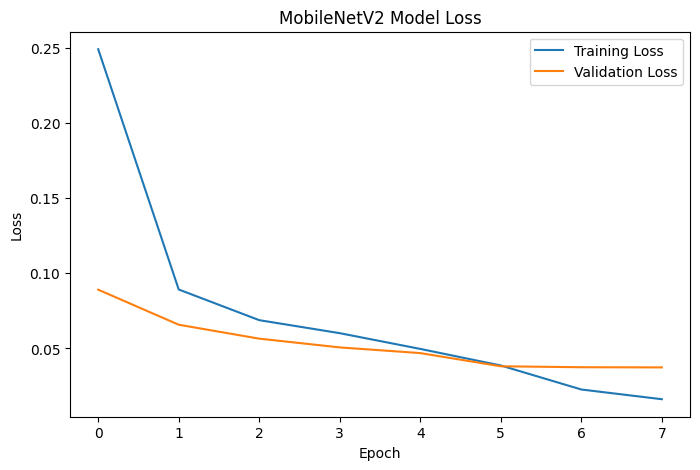

In [19]:
# Combine loss values
train_loss = (
    history.history['loss'] +
    fine_tune_history.history['loss']
)

validation_loss = (
    history.history['val_loss'] +
    fine_tune_history.history['val_loss']
)

# Plot loss
plt.figure(figsize=(8, 5))

plt.plot(train_loss, label='Training Loss')
plt.plot(validation_loss, label='Validation Loss')

plt.title('MobileNetV2 Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()